# Task 3 (Medium) – Recommendation System Analysis: Netflix Dataset

**Goal:** Build a basic **content-based recommendation model** from Netflix titles and categories.


In [ ]:
import re, unicodedata, difflib
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.preprocessing import normalize, MultiLabelBinarizer
from sklearn.decomposition import TruncatedSVD

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
RED, DARK = "#E50914", "#221F1F"
pd.set_option("display.max_colwidth", 60); pd.set_option("display.width", 200)

df = pd.read_csv(r"D:\Ausify_internship_task\data\Dataset.csv", parse_dates=["date_added"]).reset_index(drop=True)
print(df.shape)
df[["title", "type", "genres", "director", "country", "rating_category"]].head()

(8786, 26)


,title,type,genres,director,country,rating_category
0,Dick Johnson Is Dead,Movie,Documentaries,Kirsten Johnson,United States,Teens
1,Ganglands,TV Show,"Crime TV Shows, International TV Shows, TV Action & Adve...",Julien Leclercq,France,Adults
2,Midnight Mass,TV Show,"TV Dramas, TV Horror, TV Mysteries",Mike Flanagan,United States,Adults
3,Confessions of an Invisible Girl,Movie,"Children & Family Movies, Comedies",Bruno Garotti,Brazil,Older Kids
4,Sankofa,Movie,"Dramas, Independent Movies, International Movies",Haile Gerima,United States,Adults


## Step 1 – Extract relevant content features

#### 1.1 Harmonize genres
Netflix uses different labels for the same idea (`Dramas` vs `TV Dramas`, `Romantic Movies` vs `Romantic TV Shows`).
If left as they are, a movie and a TV show can *never* share a genre. We map the 42 raw labels onto a smaller common vocabulary.

42 raw genre labels -> 26 harmonized genres
Titles left with no genre: 69


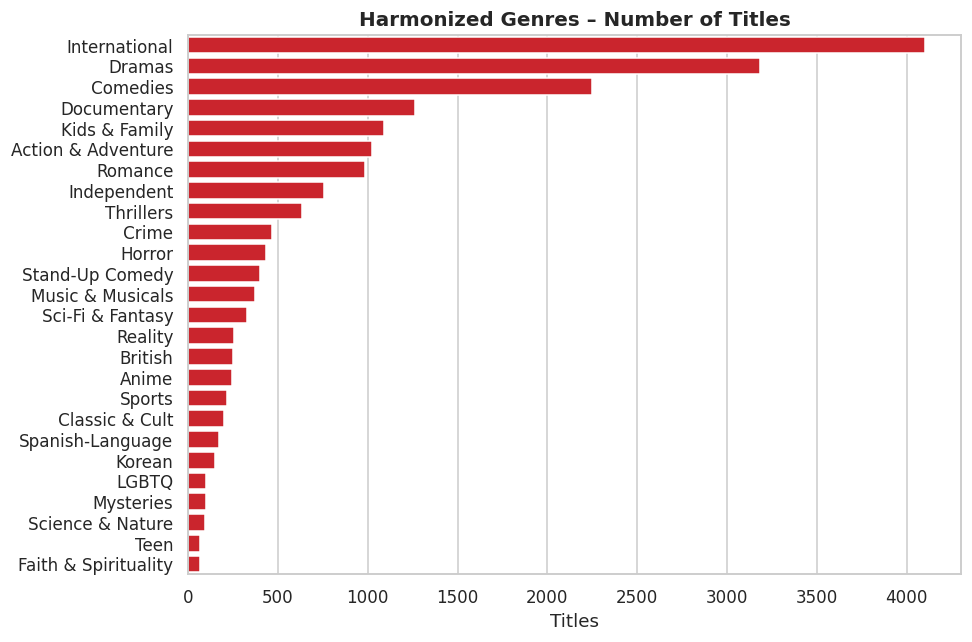

In [2]:
GENRE_MAP = {
    "International Movies": "International", "International TV Shows": "International",
    "Dramas": "Dramas", "TV Dramas": "Dramas",
    "Comedies": "Comedies", "TV Comedies": "Comedies",
    "Action & Adventure": "Action & Adventure", "TV Action & Adventure": "Action & Adventure",
    "Thrillers": "Thrillers", "TV Thrillers": "Thrillers",
    "Horror Movies": "Horror", "TV Horror": "Horror",
    "Sci-Fi & Fantasy": "Sci-Fi & Fantasy", "TV Sci-Fi & Fantasy": "Sci-Fi & Fantasy",
    "Romantic Movies": "Romance", "Romantic TV Shows": "Romance",
    "Crime TV Shows": "Crime", "TV Mysteries": "Mysteries",
    "Children & Family Movies": "Kids & Family", "Kids' TV": "Kids & Family",
    "Documentaries": "Documentary", "Docuseries": "Documentary", "Science & Nature TV": "Science & Nature",
    "Stand-Up Comedy": "Stand-Up Comedy", "Stand-Up Comedy & Talk Shows": "Stand-Up Comedy",
    "Anime Series": "Anime", "Anime Features": "Anime",
    "Classic Movies": "Classic & Cult", "Cult Movies": "Classic & Cult", "Classic & Cult TV": "Classic & Cult",
    "British TV Shows": "British", "Korean TV Shows": "Korean", "Spanish-Language TV Shows": "Spanish-Language",
    "Teen TV Shows": "Teen", "Independent Movies": "Independent", "Music & Musicals": "Music & Musicals",
    "Sports Movies": "Sports", "LGBTQ Movies": "LGBTQ", "Reality TV": "Reality", "Faith & Spirituality": "Faith & Spirituality",
    "Movies": None, "TV Shows": None,           # generic labels carry no information -> dropped
}
raw_genres = set(df["genres"].str.split(", ").explode())
assert raw_genres <= set(GENRE_MAP), raw_genres - set(GENRE_MAP)

df["genre_list"] = df["genres"].apply(
    lambda s: sorted({GENRE_MAP[g] for g in s.split(", ") if GENRE_MAP[g]})
)
print(f"{len(raw_genres)} raw genre labels -> {len({v for v in GENRE_MAP.values() if v})} harmonized genres")
print(f"Titles left with no genre: {(df['genre_list'].str.len() == 0).sum()}")

genre_freq = Counter(g for l in df["genre_list"] for g in l)
gf = pd.Series(genre_freq).sort_values(ascending=False)
plt.figure(figsize=(9, 6)); sns.barplot(x=gf.values, y=gf.index, color=RED)
plt.title("Harmonized Genres – Number of Titles"); plt.xlabel("Titles"); plt.ylabel("")
plt.tight_layout(); plt.show()

## Step 2 – Text preprocessing

In [3]:
def clean_text(text):
    """Free-text preprocessing used for titles."""
    text = unicodedata.normalize("NFKD", str(text)).encode("ascii", "ignore").decode().lower()
    text = re.sub(r"[^a-z\s]", " ", text)                                     # punctuation + digits out
    tokens = [t for t in text.split() if len(t) > 1 and t not in ENGLISH_STOP_WORDS]
    tokens = [t[:-1] if len(t) > 3 and t.endswith("s") and not t.endswith("ss") else t for t in tokens]  # light stemming
    return " ".join(tokens)

def slug(s):
    return re.sub(r"[^a-z0-9]+", "_", str(s).lower()).strip("_")

demo = ["The Lord of the Rings: The Return of the King", "Tremors 5:  Bloodline", "Chhota Bheem & the Curse of Damyaan", "Marvel's The Punisher"]
pd.DataFrame({"raw title": demo, "cleaned": [clean_text(t) for t in demo]})

,raw title,cleaned
0,The Lord of the Rings: The Return of the King,lord ring return king
1,Tremors 5: Bloodline,tremor bloodline
2,Chhota Bheem & the Curse of Damyaan,chhota bheem curse damyaan
3,Marvel's The Punisher,marvel punisher


In [4]:
# One function per feature block: DataFrame -> Series of token strings
FIELDS = {
    "genre":    lambda d: d["genre_list"].apply(lambda l: " ".join(slug(g) for g in l)),
    "director": lambda d: d["director"].apply(lambda s: "" if s == "Unknown" else " ".join(slug(x) for x in s.split(", "))),
    "country":  lambda d: d["country"].apply(lambda s: "" if s == "Unknown" else slug(s)),
    "format":   lambda d: "type_" + d["type"].apply(slug),
    "audience": lambda d: "rating_" + d["rating_category"].apply(slug),
    "era":      lambda d: "decade_" + d["release_decade"].astype(str),
    "title":    lambda d: d["title"].apply(clean_text),
}
pd.DataFrame({k: f(df.iloc[[1]]).values for k, f in FIELDS.items()}, index=[df.loc[1, "title"]]).T

,Ganglands
genre,action_adventure crime international
director,julien_leclercq
country,france
format,type_tv_show
audience,rating_adults
era,decade_2020s
title,gangland


## Step 3 – Calculate content similarity

In [5]:
WEIGHTS = {"genre": 2.0, "director": 1.5, "country": 1.0, "format": 0.8, "audience": 0.8, "title": 1.0, "era": 0.4}

class ContentRecommender:
    """Weighted multi-field TF-IDF content model (cosine similarity)."""
    def __init__(self, weights):
        self.weights = {k: w for k, w in weights.items() if w > 0}
    def _vec(self):
        return TfidfVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False, sublinear_tf=True)
    def fit(self, d):
        self.vecs = {k: self._vec().fit(FIELDS[k](d)) for k in self.weights}
        self.X = self.query(d)
        return self
    def query(self, d):
        blocks = [self.weights[k] * v.transform(FIELDS[k](d)) for k, v in self.vecs.items()]
        return normalize(sp.hstack(blocks).tocsr())

class SoupRecommender:
    """Classic baseline: concatenate everything into one string, count words, cosine."""
    def _soup(self, d):
        parts = [FIELDS[k](d) for k in ["genre", "director", "country", "format", "audience", "title"]]
        return parts[0].str.cat(parts[1:], sep=" ")
    def fit(self, d):
        self.vec = CountVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False).fit(self._soup(d))
        self.X = self.query(d); return self
    def query(self, d):
        return normalize(self.vec.transform(self._soup(d)).astype(float))

model   = ContentRecommender(WEIGHTS).fit(df)
genre_m = ContentRecommender({"genre": 1.0}).fit(df)
soup_m  = SoupRecommender().fit(df)

print("Feature matrix:", model.X.shape, f"| non-zeros per title: {model.X.nnz / model.X.shape[0]:.1f}")
for k, v in model.vecs.items():
    print(f"  {k:9s} vocabulary size = {len(v.vocabulary_):>6,}   weight = {WEIGHTS[k]}")

Feature matrix: (8786, 13135) | non-zeros per title: 9.2
  genre     vocabulary size =     26   weight = 2.0
  director  vocabulary size =  4,987   weight = 1.5
  country   vocabulary size =     85   weight = 1.0
  format    vocabulary size =      2   weight = 0.8
  audience  vocabulary size =      5   weight = 0.8
  title     vocabulary size =  8,020   weight = 1.0
  era       vocabulary size =     10   weight = 0.4


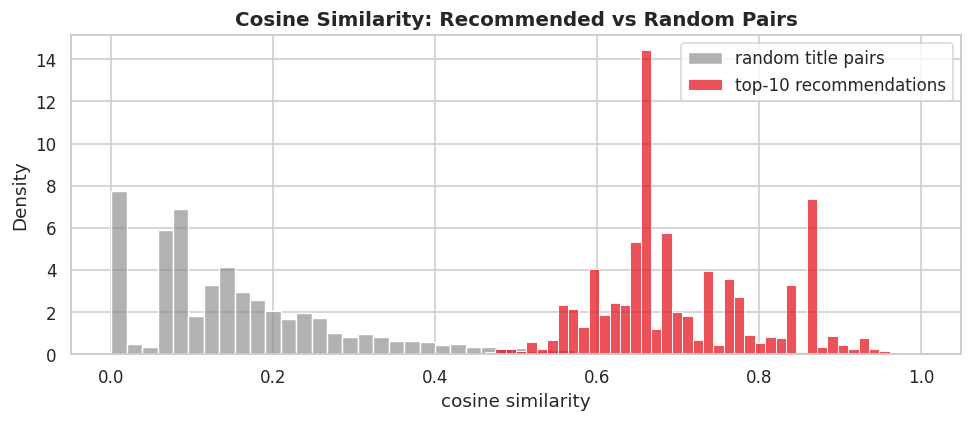

Median similarity – random pairs: 0.132 | top-10 recommendations: 0.672


In [6]:
# Similarity of one title to the whole catalogue = one sparse dot product
def sim_row(m, q):                      # q: 1 x features sparse matrix
    return (q @ m.X.T).toarray().ravel()

# Distribution of similarity scores: top-10 neighbours vs random pairs
rng = np.random.default_rng(0)
sample = rng.choice(len(df), 600, replace=False)
S = (model.X[sample] @ model.X.T).toarray()
S[np.arange(len(sample)), sample] = -1
top10 = -np.sort(-S, axis=1)[:, :10]
rand_pairs = S[S > -1][rng.choice(S.size - len(sample), 50000, replace=False)]

plt.figure(figsize=(9, 4))
sns.histplot(rand_pairs, bins=50, stat="density", color="grey", label="random title pairs", alpha=0.6)
sns.histplot(top10.ravel(), bins=50, stat="density", color=RED, label="top-10 recommendations", alpha=0.7)
plt.title("Cosine Similarity: Recommended vs Random Pairs"); plt.xlabel("cosine similarity"); plt.legend()
plt.tight_layout(); plt.show()
print(f"Median similarity – random pairs: {np.median(rand_pairs):.3f} | top-10 recommendations: {np.median(top10):.3f}")

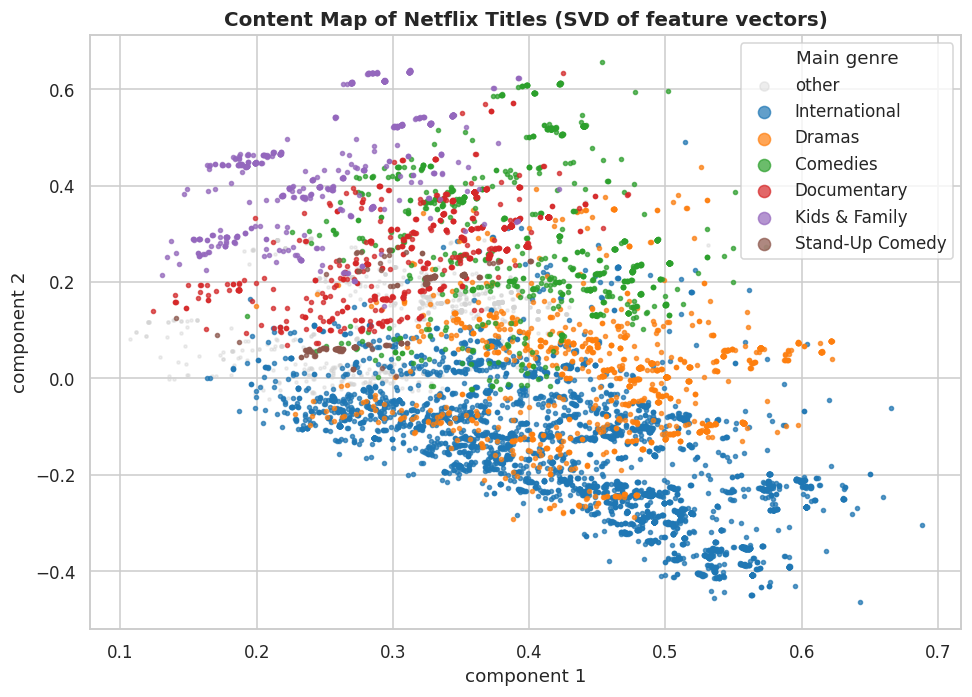

In [7]:
# 2-D map of the catalogue (SVD projection of the feature vectors), coloured by main genre
svd = TruncatedSVD(n_components=2, random_state=42).fit_transform(model.X)
main_genre = df["genre_list"].apply(lambda l: max(l, key=genre_freq.get) if l else "None")
show = main_genre.value_counts().head(6).index

plt.figure(figsize=(9, 6.5))
plt.scatter(svd[:, 0], svd[:, 1], s=4, c="lightgrey", alpha=0.4, label="other")
for g, c in zip(show, sns.color_palette("tab10", len(show))):
    mk = (main_genre == g).values
    plt.scatter(svd[mk, 0], svd[mk, 1], s=7, color=c, alpha=0.7, label=g)
plt.legend(markerscale=3, title="Main genre"); plt.title("Content Map of Netflix Titles (SVD of feature vectors)")
plt.xlabel("component 1"); plt.ylabel("component 2")
plt.tight_layout(); plt.show()

The histogram shows the model separates 'similar' from 'unrelated' pairs (the red top-10 scores sit far to the right of random pairs), and the content map shows titles organizing into genre-driven regions.

## Step 4 – Generate recommendations for selected titles

In [8]:
title_lookup = {t.lower(): i for i, t in reversed(list(enumerate(df["title"])))}   # first occurrence wins

def find_title(name):
    key = name.lower().strip()
    if key in title_lookup:
        return title_lookup[key]
    close = difflib.get_close_matches(key, title_lookup.keys(), n=1, cutoff=0.6)
    if not close:
        raise ValueError(f"'{name}' not found")
    print(f"'{name}' not found exactly – using closest match: '{df.loc[title_lookup[close[0]], 'title']}'")
    return title_lookup[close[0]]

def recommend(name, k=10, m=None, same_type=None):
    """Top-k most similar titles. same_type: None (any), 'Movie' or 'TV Show', or True to match the query's type."""
    m = m or model
    i = find_title(name)
    s = sim_row(m, m.X[i])
    s[i] = -1                                              # never recommend the title itself
    if same_type is True:  same_type = df.loc[i, "type"]
    if same_type:          s[(df["type"] != same_type).values] = -1
    idx = np.argsort(-s)[:k]
    out = df.loc[idx, ["title", "type", "genres", "country", "release_year"]].copy()
    out.insert(0, "similarity", s[idx].round(3))
    return out.reset_index(drop=True)

def show(name, k=10, **kw):
    i = find_title(name)
    print(f"▶ {df.loc[i, 'title']}  [{df.loc[i, 'type']}]  |  {df.loc[i, 'genres']}  |  {df.loc[i, 'country']}")
    display(recommend(name, k, **kw))

show("Stranger Things")

▶ Stranger Things  [TV Show]  |  TV Horror, TV Mysteries, TV Sci-Fi & Fantasy  |  United States


,similarity,title,type,genres,country,release_year
0,0.864,Beyond Stranger Things,TV Show,"Stand-Up Comedy & Talk Shows, TV Mysteries, TV Sci-Fi & ...",United States,2017
1,0.844,Chilling Adventures of Sabrina,TV Show,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy",United States,2020
2,0.810,The 4400,TV Show,"TV Dramas, TV Mysteries, TV Sci-Fi & Fantasy",United States,2007
3,0.780,Nightflyers,TV Show,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy",United States,2018
4,0.780,Helix,TV Show,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy",United States,2015
5,0.776,The Vampire Diaries,TV Show,"TV Dramas, TV Mysteries, TV Sci-Fi & Fantasy",United States,2016
6,0.776,The Messengers,TV Show,"TV Dramas, TV Mysteries, TV Sci-Fi & Fantasy",United States,2015
7,0.764,The Originals,TV Show,"TV Dramas, TV Horror, TV Mysteries",United States,2018
8,0.754,Manifest,TV Show,"TV Dramas, TV Mysteries, TV Sci-Fi & Fantasy",United States,2021
9,0.731,The Umbrella Academy,TV Show,"TV Action & Adventure, TV Mysteries, TV Sci-Fi & Fantasy",United States,2020


In [9]:
show("The Crown")

▶ The Crown  [TV Show]  |  British TV Shows, International TV Shows, TV Dramas  |  United Kingdom


,similarity,title,type,genres,country,release_year
0,0.866,Behind Her Eyes,TV Show,"British TV Shows, International TV Shows, TV Dramas",United Kingdom,2021
1,0.844,Black Earth Rising,TV Show,"British TV Shows, International TV Shows, TV Dramas",United Kingdom,2018
2,0.844,Traitors,TV Show,"British TV Shows, International TV Shows, TV Dramas",United Kingdom,2019
3,0.844,Black Mirror,TV Show,"British TV Shows, International TV Shows, TV Dramas",United Kingdom,2019
4,0.844,Requiem,TV Show,"British TV Shows, International TV Shows, TV Dramas",United Kingdom,2018
5,0.780,Dracula,TV Show,"British TV Shows, International TV Shows, TV Dramas",United Kingdom,2020
6,0.780,The English Game,TV Show,"British TV Shows, International TV Shows, TV Dramas",United Kingdom,2020
7,0.780,The A List,TV Show,"British TV Shows, International TV Shows, TV Dramas",United Kingdom,2021
8,0.775,After Life,TV Show,"British TV Shows, International TV Shows, TV Comedies",United Kingdom,2020
9,0.775,The Windsors,TV Show,"British TV Shows, International TV Shows, TV Comedies",United Kingdom,2020


In [10]:
show("Kung Fu Panda", same_type=None)

▶ Kung Fu Panda  [Movie]  |  Children & Family Movies, Comedies  |  United States


,similarity,title,type,genres,country,release_year
0,0.751,Kung Fu Panda 2,Movie,"Children & Family Movies, Comedies",United States,2011
1,0.740,The Spooky Tale of Captain Underpants Hack-a-ween,Movie,"Children & Family Movies, Comedies",United States,2019
2,0.740,Captain Underpants Epic Choice-o-Rama,Movie,"Children & Family Movies, Comedies",United States,2020
3,0.739,Kung Fu Panda: Holiday,Movie,"Children & Family Movies, Comedies",United States,2010
4,0.727,Kung Fu Panda: Secrets of the Scroll,Movie,"Children & Family Movies, Comedies",United States,2016
5,0.714,The Who Was? Show,TV Show,"Kids' TV, TV Comedies",United States,2018
6,0.702,"Yours, Mine and Ours",Movie,"Children & Family Movies, Comedies",United States,2005
7,0.683,What's New Scooby-Doo?,TV Show,"Kids' TV, TV Comedies",United States,2005
8,0.683,DreamWorks Happy Holidays from Madagascar,TV Show,"Kids' TV, TV Comedies",United States,2005
9,0.683,DreamWorks Spooky Stories,TV Show,"Kids' TV, TV Comedies",United States,2009


In [11]:
show("Dangal")

▶ Dangal  [Movie]  |  Dramas, International Movies, Sports Movies  |  India


,similarity,title,type,genres,country,release_year
0,0.665,Patiala House,Movie,"Dramas, International Movies, Sports Movies",India,2011
1,0.665,Mary Kom,Movie,"Dramas, International Movies, Sports Movies",India,2014
2,0.622,'89,Movie,Sports Movies,United Kingdom,2017
3,0.599,Bathinda Express,Movie,"Dramas, International Movies, Sports Movies",India,2016
4,0.599,Khido Khundi,Movie,"Dramas, International Movies, Sports Movies",India,2018
5,0.599,Soorma,Movie,"Dramas, International Movies, Sports Movies",India,2018
6,0.599,Lorai: Play to Live,Movie,"Dramas, International Movies, Sports Movies",India,2015
7,0.599,Kai Po Che!,Movie,"Dramas, International Movies, Sports Movies",India,2013
8,0.599,Jada,Movie,"Dramas, International Movies, Sports Movies",India,2019
9,0.599,Azhar,Movie,"Dramas, International Movies, Sports Movies",India,2016


In [12]:
show("Naruto")

▶ Naruto  [TV Show]  |  Anime Series, International TV Shows  |  Japan


,similarity,title,type,genres,country,release_year
0,0.758,InuYasha,TV Show,"Anime Series, International TV Shows",Japan,2001
1,0.758,Fullmetal Alchemist,TV Show,"Anime Series, International TV Shows",Japan,2003
2,0.758,Soul Eater,TV Show,"Anime Series, International TV Shows",Japan,2008
3,0.758,Bleach,TV Show,"Anime Series, International TV Shows",Japan,2006
4,0.758,Gurren Lagann,TV Show,"Anime Series, International TV Shows",Japan,2007
5,0.740,Revisions,TV Show,"Anime Series, International TV Shows",Japan,2018
6,0.740,The Seven Deadly Sins,TV Show,"Anime Series, International TV Shows",Japan,2021
7,0.740,Magi: Adventure of Sinbad,TV Show,"Anime Series, International TV Shows",Japan,2016
8,0.740,Pop Team Epic,TV Show,"Anime Series, International TV Shows",Japan,2018
9,0.740,Rurouni Kenshin,TV Show,"Anime Series, International TV Shows",Japan,1998


In [13]:
show("Our Planet")

▶ Our Planet  [TV Show]  |  Docuseries, Science & Nature TV  |  United Kingdom


,similarity,title,type,genres,country,release_year
0,0.873,The Making of Frozen Planet,TV Show,"British TV Shows, Docuseries, Science & Nature TV",United Kingdom,2012
1,0.818,The Hunt,TV Show,"British TV Shows, Docuseries, Science & Nature TV",United Kingdom,2015
2,0.812,Planet Earth II,TV Show,"British TV Shows, Docuseries, Science & Nature TV",United Kingdom,2016
3,0.812,Blue Planet II,TV Show,"British TV Shows, Docuseries, Science & Nature TV",United Kingdom,2017
4,0.802,Nature's Great Events: Diaries,TV Show,"British TV Shows, Docuseries, Science & Nature TV",United Kingdom,2009
5,0.802,Nature's Great Events (2009),TV Show,"British TV Shows, Docuseries, Science & Nature TV",United Kingdom,2009
6,0.758,Nature: Animals With Cameras,TV Show,"Docuseries, Science & Nature TV",United Kingdom,2018
7,0.758,Great Yellowstone Thaw,TV Show,"Docuseries, Science & Nature TV",United Kingdom,2017
8,0.752,Life Story,TV Show,"British TV Shows, Docuseries, Science & Nature TV",United Kingdom,2014
9,0.745,Monkey Planet,TV Show,"British TV Shows, Docuseries, Science & Nature TV",United Kingdom,2014


In [14]:
# Same query, restricted to the same format
show("Stranger Things", k=5, same_type=True)

▶ Stranger Things  [TV Show]  |  TV Horror, TV Mysteries, TV Sci-Fi & Fantasy  |  United States


,similarity,title,type,genres,country,release_year
0,0.864,Beyond Stranger Things,TV Show,"Stand-Up Comedy & Talk Shows, TV Mysteries, TV Sci-Fi & ...",United States,2017
1,0.844,Chilling Adventures of Sabrina,TV Show,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy",United States,2020
2,0.810,The 4400,TV Show,"TV Dramas, TV Mysteries, TV Sci-Fi & Fantasy",United States,2007
3,0.780,Helix,TV Show,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy",United States,2015
4,0.780,Nightflyers,TV Show,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy",United States,2018


### 4.1 Recommendations for a *user profile* (several liked titles)

In [15]:
def recommend_for_profile(liked, k=10, same_type=None):
    idx = [find_title(t) for t in liked]
    profile = normalize(sp.csr_matrix(model.X[idx].mean(axis=0)))       # average taste vector
    s = sim_row(model, profile)
    s[idx] = -1
    if same_type: s[(df["type"] != same_type).values] = -1
    top = np.argsort(-s)[:k]
    out = df.loc[top, ["title", "type", "genres", "country"]].copy()
    out.insert(0, "similarity", s[top].round(3))
    return out.reset_index(drop=True)

print("User liked: Breaking Bad, Narcos, Ozark")
display(recommend_for_profile(["Breaking Bad", "Narcos", "Ozark"]))

User liked: Breaking Bad, Narcos, Ozark


,similarity,title,type,genres,country
0,0.887,When They See Us,TV Show,"Crime TV Shows, TV Dramas",United States
1,0.879,Dare Me,TV Show,"Crime TV Shows, TV Dramas, TV Thrillers",United States
2,0.879,The Assassination of Gianni Versace,TV Show,"Crime TV Shows, TV Dramas, TV Thrillers",United States
3,0.879,Designated Survivor,TV Show,"Crime TV Shows, TV Dramas, TV Thrillers",United States
4,0.826,Marvel's The Punisher,TV Show,"Crime TV Shows, TV Action & Adventure, TV Thrillers",United States
5,0.825,Unbelievable,TV Show,"Crime TV Shows, TV Dramas",United States
6,0.825,Hap and Leonard,TV Show,"Crime TV Shows, TV Dramas",United States
7,0.825,Longmire,TV Show,"Crime TV Shows, TV Dramas",United States
8,0.825,American Crime,TV Show,"Crime TV Shows, TV Dramas",United States
9,0.825,Seven Seconds,TV Show,"Crime TV Shows, TV Dramas",United States


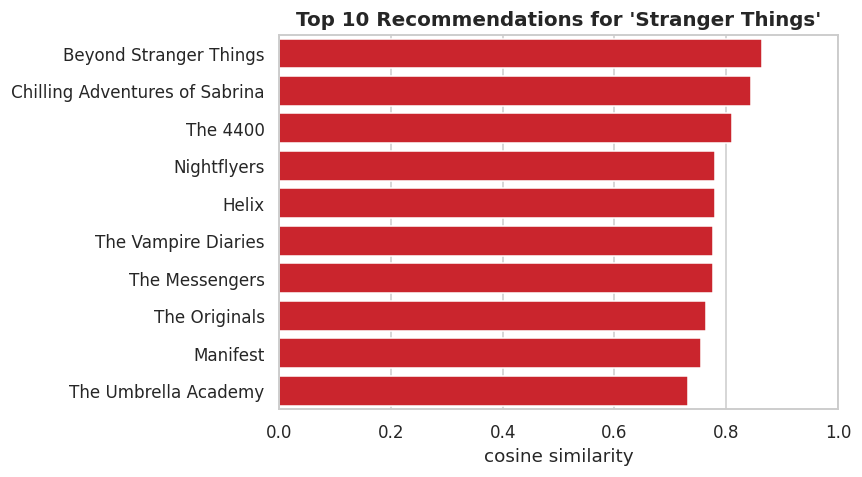

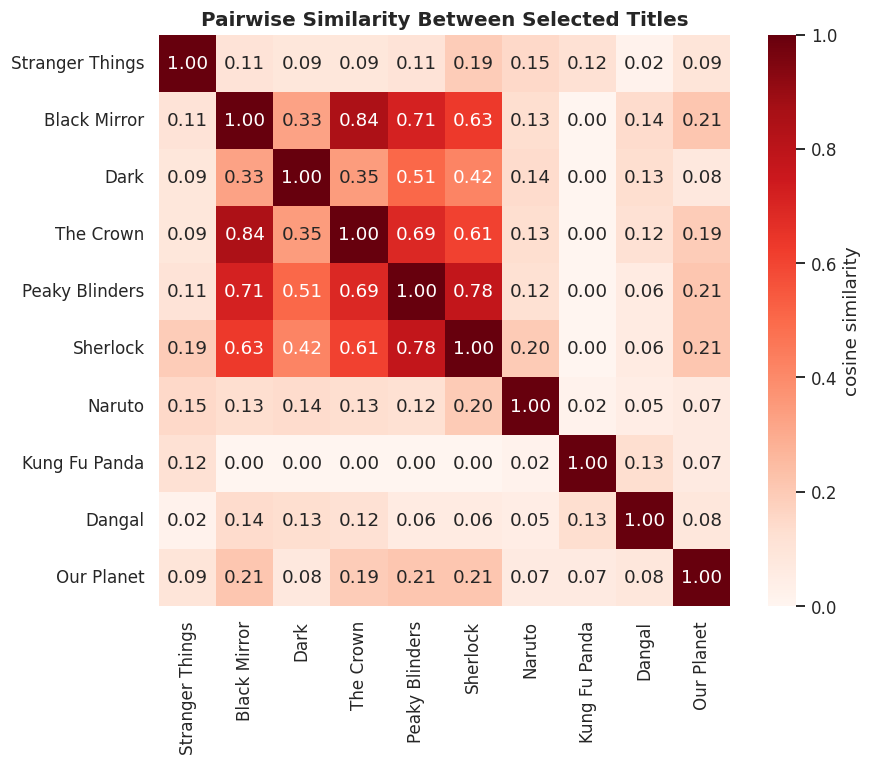

In [16]:
# Visual: similarity scores of the top 10 for one title
r = recommend("Stranger Things", 10)
plt.figure(figsize=(8, 4.5))
sns.barplot(x=r["similarity"], y=r["title"], color=RED); plt.xlim(0, 1)
plt.title("Top 10 Recommendations for 'Stranger Things'"); plt.xlabel("cosine similarity"); plt.ylabel("")
plt.tight_layout(); plt.show()

# Similarity between a handful of well-known titles
picks = ["Stranger Things", "Black Mirror", "Dark", "The Crown", "Peaky Blinders", "Sherlock", "Naruto", "Kung Fu Panda", "Dangal", "Our Planet"]
ix = [find_title(t) for t in picks]
M = (model.X[ix] @ model.X[ix].T).toarray()
plt.figure(figsize=(8.5, 7))
sns.heatmap(pd.DataFrame(M, index=picks, columns=picks), annot=True, fmt=".2f", cmap="Reds", square=True, cbar_kws={"label": "cosine similarity"})
plt.title("Pairwise Similarity Between Selected Titles"); plt.tight_layout(); plt.show()

## Step 5 – Evaluate recommendation quality

There are **no user ratings or watch histories**, so classic metrics (RMSE, precision against what users actually watched) are not possible. Quality is judged with **offline proxy metrics** over 1,500 randomly chosen query titles (k = 10, the title itself is never recommended):


> **Caveat:** genre is part of the model's input *and* of the relevance definition, so genre metrics are partly circular. Section 5.2 therefore also **removes one feature block at a time** and measures whether the remaining features still recover the held-out attribute, which is a non-circular check.

In [17]:
K = 10
rng = np.random.default_rng(42)
test_idx = rng.choice(np.flatnonzero(df["genre_list"].str.len() > 0), 1500, replace=False)

mlb = MultiLabelBinarizer(); G = mlb.fit_transform(df["genre_list"]).astype(float)
type_arr = df["type"].to_numpy(dtype=object)
aud_arr  = df["rating_category"].to_numpy(dtype=object)
ctry_arr = df["country"].to_numpy(dtype=object)
known_c  = ctry_arr[test_idx] != "Unknown"

def topk(S, k=K):
    idx = np.argpartition(-S, k, axis=1)[:, :k]
    order = np.argsort(-np.take_along_axis(S, idx, 1), axis=1)
    return np.take_along_axis(idx, order, 1)

def recs_for(m, rows, chunk=500):
    """Top-K neighbours (excluding the title itself) for the given catalogue rows."""
    out = []
    for a in range(0, len(rows), chunk):
        r = rows[a:a + chunk]
        S = (m.X[r] @ m.X.T).toarray()
        S[np.arange(len(r)), r] = -1
        out.append(topk(S))
    return np.vstack(out)

def genre_diversity(rec):
    vals = []
    for r in rec:
        g = G[r]; inter = g @ g.T; sz = g.sum(1)
        union = sz[:, None] + sz[None, :] - inter
        jac = np.divide(inter, union, out=np.zeros_like(inter), where=union > 0)
        vals.append(1 - (jac.sum() - np.trace(jac)) / (K * (K - 1)))
    return float(np.mean(vals))

def metrics(rec):
    Gq, Gr = G[test_idx], G[rec]
    inter = np.einsum("qg,qkg->qk", Gq, Gr)
    union = Gq.sum(1)[:, None] + Gr.sum(2) - inter
    return {
        "Genre precision@10": (inter > 0).mean(),
        "Mean genre Jaccard": (inter / np.maximum(union, 1)).mean(),
        "Same-type rate":     (type_arr[rec] == type_arr[test_idx][:, None]).mean(),
        "Same-audience rate": (aud_arr[rec]  == aud_arr[test_idx][:, None]).mean(),
        "Same-country rate":  (ctry_arr[rec][known_c] == ctry_arr[test_idx][known_c][:, None]).mean(),
        "Genre diversity":    genre_diversity(rec),
    }

def coverage(m, chunk=500):
    seen = np.zeros(len(df), bool)
    for a in range(0, len(df), chunk):
        rows = np.arange(a, min(a + chunk, len(df)))
        seen[recs_for(m, rows).ravel()] = True
    return seen.mean()

rand_rec = np.stack([rng.choice(np.delete(np.arange(len(df)), p), K, replace=False) for p in test_idx])
results = {
    "Random":                 metrics(rand_rec),
    "Genre-only":             metrics(recs_for(genre_m, test_idx)),
    "Bag-of-words 'soup'":    metrics(recs_for(soup_m,  test_idx)),
    "Weighted TF-IDF (ours)": metrics(recs_for(model,   test_idx)),
}
res = pd.DataFrame(results).T
res["Catalogue coverage"] = [np.nan, coverage(genre_m), coverage(soup_m), coverage(model)]
res.round(3)

,Genre precision@10,Mean genre Jaccard,Same-type rate,Same-audience rate,Same-country rate,Genre diversity,Catalogue coverage
Random,0.413,0.152,0.586,0.342,0.168,0.852,NaN
Genre-only,1.000,0.973,0.800,0.475,0.368,0.025,0.588
Bag-of-words 'soup',0.994,0.838,0.988,0.959,0.814,0.216,0.866
Weighted TF-IDF (ours),1.000,0.912,0.910,0.862,0.789,0.112,0.927


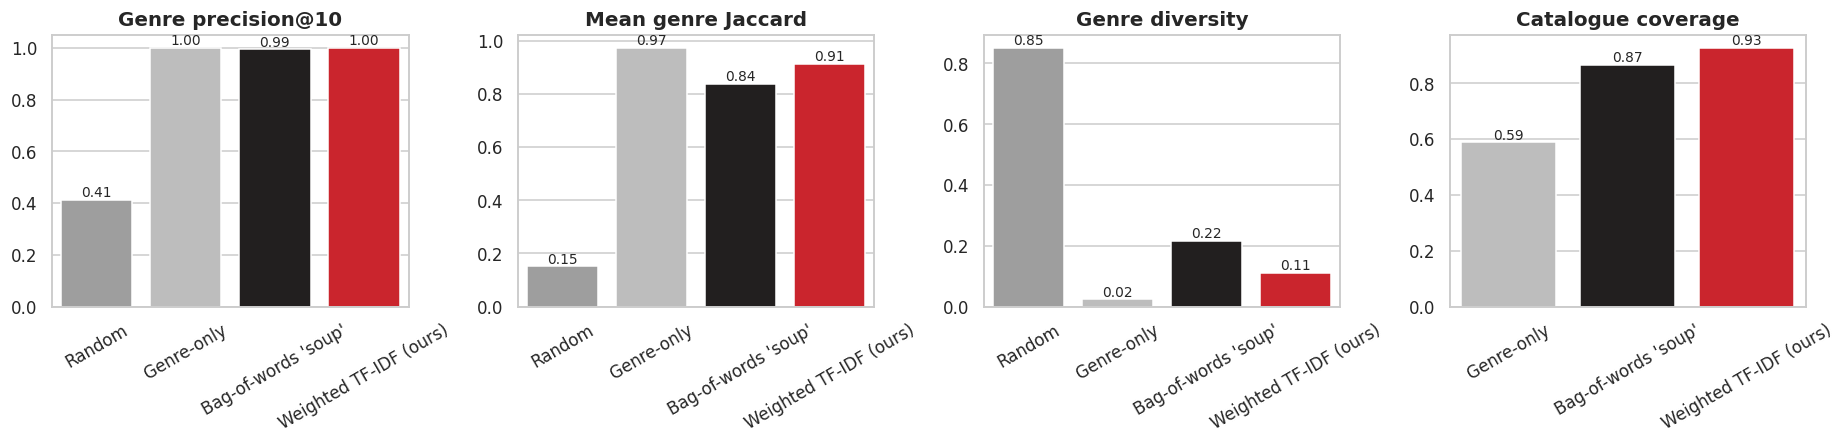

In [18]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
palette = ["#9e9e9e", "#bdbdbd", DARK, RED]
for ax, col in zip(axes, ["Genre precision@10", "Mean genre Jaccard", "Genre diversity", "Catalogue coverage"]):
    d = res[col].dropna()
    sns.barplot(x=d.index, y=d.values, hue=d.index, palette=dict(zip(res.index, palette)), ax=ax, legend=False)
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=9)
    ax.set_title(col); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

### 5.2 Feature ablation / held-out-field test

Each row rebuilds the model **without** one feature block. If recommendations still agree with the query on the removed attribute, the remaining features carry that signal; if agreement collapses, the removed block was doing the work.

,Genre precision@10,Mean genre Jaccard,Same-country rate,Same-audience rate,Same-type rate
Random,0.413,0.152,0.168,0.342,0.586
Full model,1.000,0.912,0.789,0.862,0.910
– without genre,0.612,0.310,0.956,0.944,0.970
– without director,1.000,0.925,0.785,0.901,0.973
– without country,1.000,0.922,0.375,0.910,0.865
– without format,1.000,0.905,0.781,0.865,0.714
– without audience,1.000,0.921,0.808,0.508,0.915
– without title,1.000,0.912,0.788,0.854,0.888
– without era,1.000,0.912,0.791,0.858,0.897


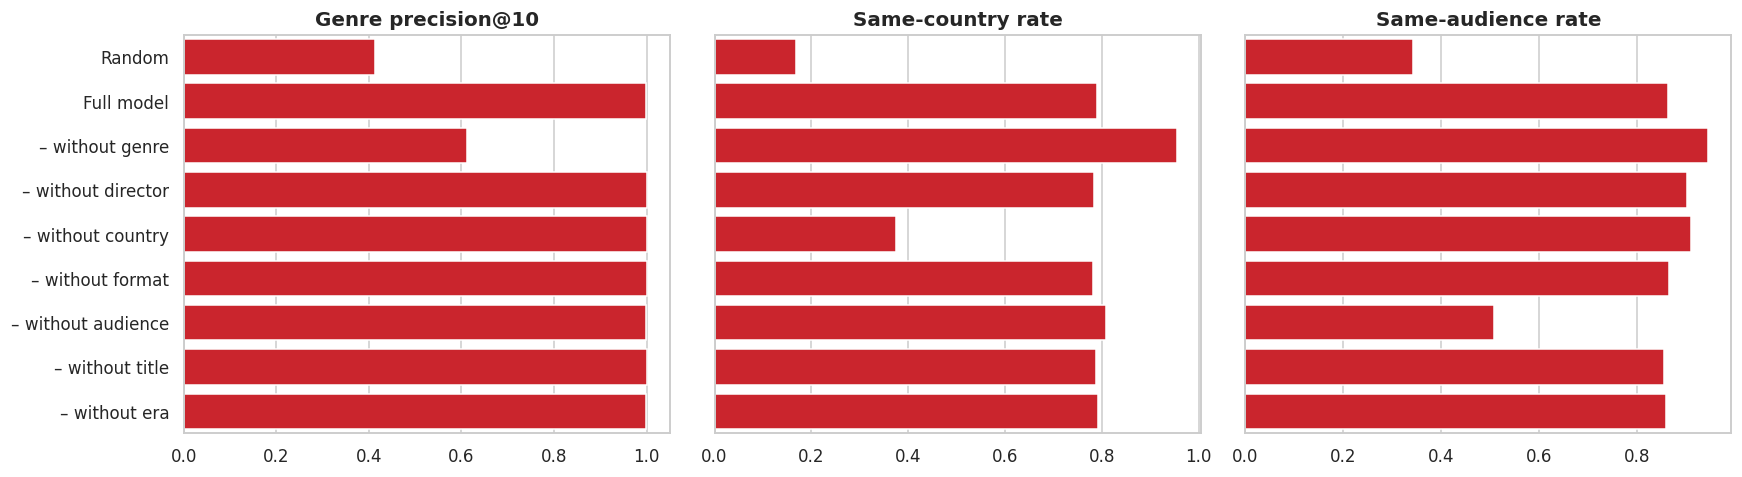

In [19]:
abl = {"Random": results["Random"], "Full model": results["Weighted TF-IDF (ours)"]}
for block in WEIGHTS:
    m = ContentRecommender({k: v for k, v in WEIGHTS.items() if k != block}).fit(df)
    abl[f"– without {block}"] = metrics(recs_for(m, test_idx))

abl_df = pd.DataFrame(abl).T[["Genre precision@10", "Mean genre Jaccard", "Same-country rate", "Same-audience rate", "Same-type rate"]]
display(abl_df.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, col in zip(axes, ["Genre precision@10", "Same-country rate", "Same-audience rate"]):
    sns.barplot(x=abl_df[col].values, y=abl_df.index, color=RED, ax=ax)
    ax.set_title(col); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

### 5.3 Does the model respect audience suitability?

In [20]:
rec_all = recs_for(model, test_idx)
adult_share = (aud_arr[rec_all] == "Adults")
kid_q = aud_arr[test_idx] == "Kids"
chance_aud = (df["rating_category"].value_counts(normalize=True) ** 2).sum()

print(f"Same audience category as the query: {(aud_arr[rec_all] == aud_arr[test_idx][:, None]).mean():.1%}  (chance level: {chance_aud:.1%})")
print(f"'Adults'-rated titles among recommendations for Kids-rated queries: {adult_share[kid_q].mean():.1%}  (share of Adults in the catalogue: {(aud_arr == 'Adults').mean():.1%})")

Same audience category as the query: 86.2%  (chance level: 33.1%)
'Adults'-rated titles among recommendations for Kids-rated queries: 6.3%  (share of Adults in the catalogue: 45.6%)


### 5.4 Weight sensitivity – the precision / relevance trade-off

The block weights are a tunable design choice. Sweeping the **genre weight** shows the trade-off: a higher genre weight gives recommendations that match the query's genres more tightly, but they agree less on country, audience and format and become more repetitive.

,Genre precision@10,Mean genre Jaccard,Same-type rate,Same-audience rate,Same-country rate,Genre diversity,Catalogue coverage
genre weight,,,,,,,
1.0,0.978,0.739,0.961,0.930,0.927,0.326,0.947
1.5,0.998,0.852,0.929,0.894,0.846,0.189,0.935
2.0,1.000,0.912,0.910,0.862,0.789,0.112,0.927
3.0,1.000,0.955,0.873,0.830,0.725,0.053,0.902
5.0,1.000,0.972,0.862,0.813,0.681,0.028,0.888


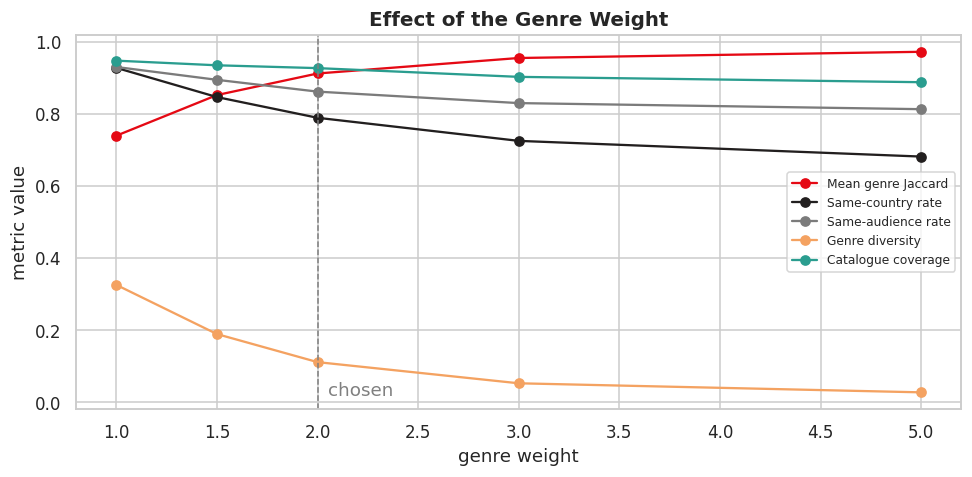

In [21]:
sweep = {}
for gw in [1, 1.5, 2, 3, 5]:
    m = ContentRecommender({**WEIGHTS, "genre": gw}).fit(df)
    r = metrics(recs_for(m, test_idx)); r["Catalogue coverage"] = coverage(m)
    sweep[gw] = r
sweep_df = pd.DataFrame(sweep).T; sweep_df.index.name = "genre weight"
display(sweep_df.round(3))

fig, ax = plt.subplots(figsize=(9, 4.5))
for col, c in zip(["Mean genre Jaccard", "Same-country rate", "Same-audience rate", "Genre diversity", "Catalogue coverage"],
                  [RED, DARK, "#7b7b7b", "#f4a261", "#2a9d8f"]):
    ax.plot(sweep_df.index, sweep_df[col], marker="o", label=col, color=c)
ax.axvline(WEIGHTS["genre"], color="grey", ls="--", lw=1); ax.text(WEIGHTS["genre"] + 0.05, 0.02, "chosen", color="grey")
ax.set_xlabel("genre weight"); ax.set_ylabel("metric value"); ax.set_title("Effect of the Genre Weight")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### 5.5 Improving diversity with MMR re-ranking


In [22]:
def mmr_recs(m, rows, k=K, pool=50, lam=0.7, chunk=500):
    out = []
    for a in range(0, len(rows), chunk):
        r = rows[a:a + chunk]
        S = (m.X[r] @ m.X.T).toarray(); S[np.arange(len(r)), r] = -1
        cand = np.argpartition(-S, pool, axis=1)[:, :pool]
        for qi in range(len(r)):
            c = cand[qi]; rel = S[qi, c]
            C = (m.X[c] @ m.X[c].T).toarray()
            chosen = [int(np.argmax(rel))]
            while len(chosen) < k:
                score = lam * rel - (1 - lam) * C[:, chosen].max(axis=1)
                score[chosen] = -np.inf
                chosen.append(int(np.argmax(score)))
            out.append(c[chosen])
    return np.array(out)

mmr = {"Plain ranking (λ = 1.0)": metrics(recs_for(model, test_idx))}
for lam in [0.7, 0.5]:
    mmr[f"MMR (λ = {lam})"] = metrics(mmr_recs(model, test_idx, lam=lam))
mmr_df = pd.DataFrame(mmr).T[["Genre precision@10", "Mean genre Jaccard", "Same-audience rate", "Same-country rate", "Genre diversity"]]
mmr_df.round(3)

,Genre precision@10,Mean genre Jaccard,Same-audience rate,Same-country rate,Genre diversity
Plain ranking (λ = 1.0),1.0,0.912,0.862,0.789,0.112
MMR (λ = 0.7),1.0,0.906,0.869,0.771,0.140
MMR (λ = 0.5),1.0,0.884,0.842,0.703,0.181


In [23]:
# Example: plain vs diversified list for the same title
i = find_title("The Crown")
plain = recommend("The Crown", 8)
div = df.loc[mmr_recs(model, np.array([i]), k=8, lam=0.5)[0], ["title", "type", "genres", "country"]].reset_index(drop=True)
print("PLAIN"); display(plain[["title", "genres", "country"]])
print("DIVERSIFIED (MMR, λ = 0.5)"); display(div[["title", "genres", "country"]])

PLAIN


,title,genres,country
0,Behind Her Eyes,"British TV Shows, International TV Shows, TV Dramas",United Kingdom
1,Black Earth Rising,"British TV Shows, International TV Shows, TV Dramas",United Kingdom
2,Traitors,"British TV Shows, International TV Shows, TV Dramas",United Kingdom
3,Black Mirror,"British TV Shows, International TV Shows, TV Dramas",United Kingdom
4,Requiem,"British TV Shows, International TV Shows, TV Dramas",United Kingdom
5,Dracula,"British TV Shows, International TV Shows, TV Dramas",United Kingdom
6,The English Game,"British TV Shows, International TV Shows, TV Dramas",United Kingdom
7,The A List,"British TV Shows, International TV Shows, TV Dramas",United Kingdom


DIVERSIFIED (MMR, λ = 0.5)


,title,genres,country
0,Behind Her Eyes,"British TV Shows, International TV Shows, TV Dramas",United Kingdom
1,Black Earth Rising,"British TV Shows, International TV Shows, TV Dramas",United Kingdom
2,Dracula,"British TV Shows, International TV Shows, TV Dramas",United Kingdom
3,The A List,"British TV Shows, International TV Shows, TV Dramas",United Kingdom
4,After Life,"British TV Shows, International TV Shows, TV Comedies",United Kingdom
5,The One,"British TV Shows, Crime TV Shows, International TV Shows",United Kingdom
6,Call the Midwife,"British TV Shows, International TV Shows, TV Dramas",United Kingdom
7,Sunderland 'Til I Die,"British TV Shows, Docuseries, International TV Shows",United Kingdom


## Summary of findings

In [24]:
summary = res.round(3).copy()
summary["Genre-precision lift vs random"] = (summary["Genre precision@10"] / summary.loc["Random", "Genre precision@10"]).round(2)
summary

,Genre precision@10,Mean genre Jaccard,Same-type rate,Same-audience rate,Same-country rate,Genre diversity,Catalogue coverage,Genre-precision lift vs random
Random,0.413,0.152,0.586,0.342,0.168,0.852,NaN,1.00
Genre-only,1.000,0.973,0.800,0.475,0.368,0.025,0.588,2.42
Bag-of-words 'soup',0.994,0.838,0.988,0.959,0.814,0.216,0.866,2.41
Weighted TF-IDF (ours),1.000,0.912,0.910,0.862,0.789,0.112,0.927,2.42


## Thank you 